# Corporate PD across one to five year horizons (C02)

**Question:** Can five yearly samples of Polish manufacturing firms give a corporate PD term structure, and how well does the ladder of models rank and calibrate the bankruptcy at each horizon?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- read the five horizon files of C02 and say why their event rates cannot be read as one cumulative PD curve;
- run the engine's AUC on holdouts rebuilt from the committed ROC steps, and compare the ladder on each horizon with the overfit gap and the DeLong intervals;
- run Hosmer-Lemeshow, the level test and the chi-square over bins on rebuilt holdouts, and read which model at which horizon is calibrated;
- read the cross-file transfer matrix and the pooled model with the firm-overlap caveat that limits both.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

from riskvalidation.transitions.intervals import pd_jeffreys as rate_interval
from riskvalidation.validation.calibration import pd_hosmer_lemeshow, pd_jeffreys
from riskvalidation.validation.discrimination import disc_auc
from matplotlib.colors import ListedColormap

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C02 is the PD of corporate borrowers at horizons of one to five years. The data is the UCI "Polish companies bankruptcy data" (Tomczak, 2016; owner: UCI Machine Learning Repository; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data; DOI 10.24432/C5F600): five files of financial ratios of manufacturing companies (64 ratios per company) with a bankruptcy label, each for a forecast horizon. The pipeline fitted the ladder of seven models on each file with a locked, stratified holdout, and on the five files stacked. Committed:

- `data/derived/C02/h1.json` to `h5.json`: one file per horizon, with each model's discrimination (ROC), calibration (reliability bins), overfit check and stability, the comparison of each challenger with the scorecard, the cross-file transfer and the battery of tests.
- `data/derived/C02/pooled.json`: the same for the five files stacked, with the firm-overlap caveat.
- `data/derived/C02/models-polish-horizons.json`: the protocol of the fit.

The next cell loads the seven files.

In [2]:
# Load the five horizon files, the pooled file and the models file of case C02
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C02"
horizons = ["h1", "h2", "h3", "h4", "h5"]
docs = {h: json.loads((derived / f"{h}.json").read_text(encoding="utf-8")) for h in horizons}
pooled = json.loads((derived / "pooled.json").read_text(encoding="utf-8"))
protocol = json.loads((derived / "models-polish-horizons.json").read_text(encoding="utf-8"))["fit"]
policy = rv.default_policy()
LANG = "en"
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
print("event definition:", docs["h1"]["outputs"]["counts"]["event_definition"][LANG])
print([docs[h]["outputs"]["counts"]["rows"] for h in horizons])
baked = docs["h1"]["provenance"]["riskvalidation_version"]
print("baked by riskvalidation", baked, "| installed", rv.__version__)

event definition: Bankruptcy of the company within 1 year of the financial statements (the class label of the file 5year.arff)
[5910, 9792, 10503, 10173, 7027]
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: five samples, not one cohort

Each file is a sample of companies with the financial ratios of one year and the bankruptcy status over a horizon. A tempting reading takes the five event rates as the cumulative probability of bankruptcy at one, two, three, four and five years, and reads a term structure from them, the input of a lifetime expected credit loss. That reading needs one cohort of companies followed over five years, so that the share bankrupt can only grow with the horizon. The files are **independent samples of different forecast years**, not one cohort followed through time, and the UCI page gives no company identifier and no date. The decision of the product (G22) is to read no term structure from them. The first check the data allows is the one the cumulative reading predicts: do the rates grow? The cell computes the event rate of each file with the engine's Jeffreys interval for a binomial proportion (Brown, Cai and DasGupta, 2001) and draws it against the horizon.

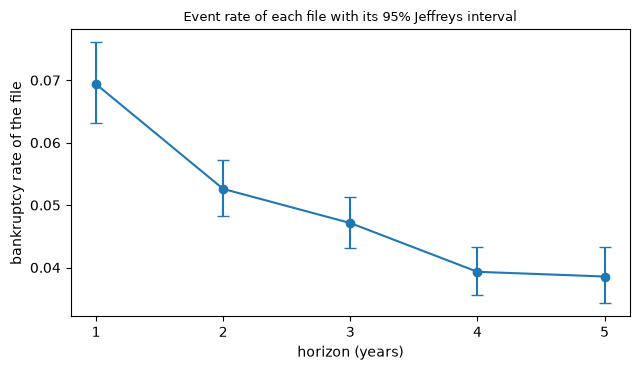

event rates by horizon: [0.0694 0.0526 0.0471 0.0393 0.0386]
the rates grow with the horizon: False


In [3]:
# The event rate of each file with the engine's Jeffreys interval: do the rates grow with the horizon?
counts = [docs[h]["outputs"]["counts"] for h in horizons]
intervals = [rate_interval(c["events"], c["rows"]) for c in counts]
rate = np.array([i["estimate"] for i in intervals])
low = rate - np.array([i["lower"] for i in intervals])
high = np.array([i["upper"] for i in intervals]) - rate
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(range(1, 6), rate, yerr=[low, high], marker="o", capsize=4)
ax.set_xticks(range(1, 6))
ax.set_xlabel("horizon (years)")
ax.set_ylabel("bankruptcy rate of the file")
ax.set_title("Event rate of each file with its 95% Jeffreys interval", fontsize=9)
fig.tight_layout()
plt.show()
print("event rates by horizon:", np.round(rate, 4))
print("the rates grow with the horizon:", bool((np.diff(rate) > 0).all()))

The event rates are 0.0694, 0.0526, 0.0471, 0.0393 and 0.0386 and they fall with the horizon, so the statement that they grow is False. The intervals are narrow enough that the first rate is clearly above the last, and the figure shows no sign of a cumulative curve: a PD that falls with the horizon is a different sample at each point, not a different time. So the expected credit loss under five horizons is not computed (the committed effect is null, with the reason), and everything below compares models horizon by horizon, never across horizons.

### Step 2: the ladder on each horizon

The seven models are the ladder of notebooks 03 and 06: a one-variable baseline (P0), the WoE scorecard (P1), a penalised logistic regression (P2a), penalised trees (P2b), an explainable boosting machine (P3) and two boosted-tree models (P4). Each file commits the ROC of every model on its holdout. From the ROC steps, with the number of bankruptcies and of healthy companies in the holdout, the cell rebuilds a vector of risk values and outcomes per model and horizon, and hands it to the engine's `disc_auc`. Within a step the order of the companies is lost, so ties count one half. The figure draws the AUC of each model against the horizon, and the cell prints the rebuilt and the committed AUC of the scorecard.

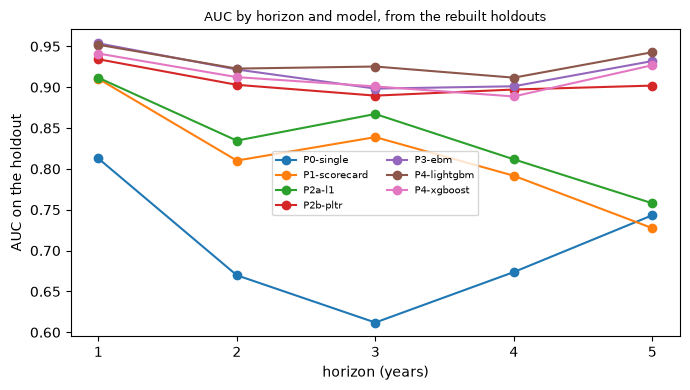

scorecard AUC, rebuilt and committed: h1 0.9104 0.9106
scorecard AUC, rebuilt and committed: h2 0.8102 0.81
scorecard AUC, rebuilt and committed: h3 0.8389 0.8388
scorecard AUC, rebuilt and committed: h4 0.7916 0.792
scorecard AUC, rebuilt and committed: h5 0.7275 0.7279


In [4]:
# Rebuild the holdout of each file from the ROC steps of every model and run the engine's AUC on it
auc = {}
for h in horizons:
    o = docs[h]["outputs"]
    n_pos = o["split"]["holdout_events"]
    n_neg = o["split"]["holdout_rows"] - n_pos
    for r in o["rungs"]:
        pos = np.rint(np.diff(r["roc"]["tpr"]) * n_pos).astype(int)
        neg = np.rint(np.diff(r["roc"]["fpr"]) * n_neg).astype(int)
        risk = np.repeat(np.arange(len(pos), 0, -1), pos + neg)
        flags = np.concatenate([np.r_[np.ones(p), np.zeros(q)] for p, q in zip(pos, neg)])
        result = disc_auc(risk, flags, policy=policy, model_id=r["model_id"])
        auc[(h, r["model_id"].split("-", 1)[1])] = (result.metric, r["discrimination"]["auc"])
rungs_ = [r["model_id"].split("-", 1)[1] for r in docs["h1"]["outputs"]["rungs"]]
fig, ax = plt.subplots(figsize=(7, 4))
for rung in rungs_:
    ax.plot(range(1, 6), [auc[(h, rung)][0] for h in horizons], marker="o", label=rung)
ax.set_xticks(range(1, 6))
ax.set_xlabel("horizon (years)")
ax.set_ylabel("AUC on the holdout")
ax.set_title("AUC by horizon and model, from the rebuilt holdouts", fontsize=9)
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()
for h in horizons:
    rebuilt, committed = auc[(h, "P1-scorecard")]
    print("scorecard AUC, rebuilt and committed:", h, round(rebuilt, 4), round(committed, 4))

The rebuilt AUC of the scorecard, 0.9104, 0.8102, 0.8389, 0.7916 and 0.7275, matches the committed one to within 0.0004. The scorecard falls from 0.91 at one year to 0.73 at five, and the richer models do not fall as much: at five years the boosted models reach 0.93 to 0.94 where the scorecard reaches 0.73. The lines for the one-variable baseline are lowest at three years. The figure should be read with its sampling error in mind: the holdout of the five-year file has 81 bankruptcies, and the AUC of the scorecard there, 0.7275, has a 95% interval from about 0.67 to 0.78.

### Step 3: the overfit gap

A model that ranks well on the data it was fitted on and worse on new data has memorised noise. The committed check compares the AUC on the training slice with the AUC on the holdout, and flags the model when the gap exceeds 0.05 AUC points, a named convention of the product (the research gives no value; the tolerance is about one and a half to three standard errors of an AUC at these holdout sizes). The cell computes the gap of every model and horizon from the committed training and holdout AUC and draws it as a grid, with an asterisk where it exceeds the tolerance.

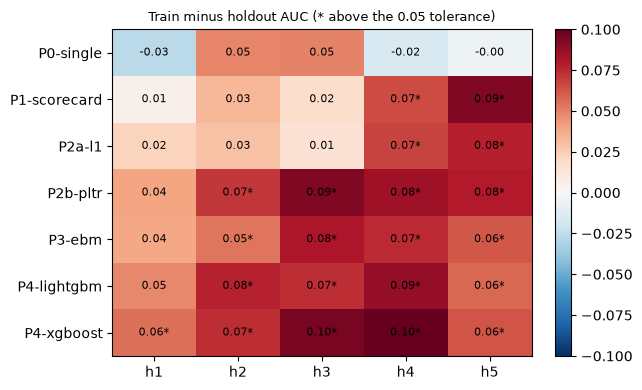

gaps above the tolerance by horizon: [1 4 4 6 6]


In [5]:
# The gap between the training AUC and the holdout AUC of each model and horizon, flagged above the tolerance
tolerance = docs["h1"]["outputs"]["parameters"][0]["value"]
gap = np.zeros((len(rungs_), len(horizons)))
for j, h in enumerate(horizons):
    for i, r in enumerate(docs[h]["outputs"]["rungs"]):
        gap[i, j] = r["overfit"]["train_auc"] - r["overfit"]["holdout_auc"]
fig, ax = plt.subplots(figsize=(6.5, 4))
image = ax.imshow(gap, cmap="RdBu_r", vmin=-0.1, vmax=0.1, aspect="auto")
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        star = "*" if gap[i, j] > tolerance else ""
        ax.text(j, i, f"{gap[i, j]:.2f}{star}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(5), horizons)
ax.set_yticks(range(len(rungs_)), rungs_)
ax.set_title("Train minus holdout AUC (* above the 0.05 tolerance)", fontsize=9)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()
print("gaps above the tolerance by horizon:", (gap > tolerance).sum(axis=0))

The number of models above the tolerance by horizon is 1, 4, 4, 6 and 6 out of seven. The scorecard itself is inside it for the first three horizons and above it at four and five years (gaps of 0.065 and 0.092), which is where its AUC is lowest: fewer bankruptcies meet 64 ratios, and the fit memorises. The richer models overfit more and rank better, in the holdout, at every horizon; the gap does not say that they are worse, it says how far the training AUC is from what a new sample gives. The one-variable baseline has no flag, by construction, since one variable cannot memorise much.

### Step 4: the challengers against the scorecard

For each horizon the file compares every challenger with the scorecard, the champion: the AUC difference with its DeLong interval. The DeLong interval is $\Delta \pm z_{0.975}\,\mathrm{SE}$, so the standard error is recovered from the interval, $\mathrm{SE} = (\mathrm{hi} - \mathrm{lo})/(2 z_{0.975})$, and the p-value follows from the same normal law as in notebook 03, $p = 2\,(1 - \Phi(|\Delta/\mathrm{SE}|))$. The figure draws the difference and its interval for the five challengers in each of the five horizons, and the cell prints the p-value of the LightGBM challenger.

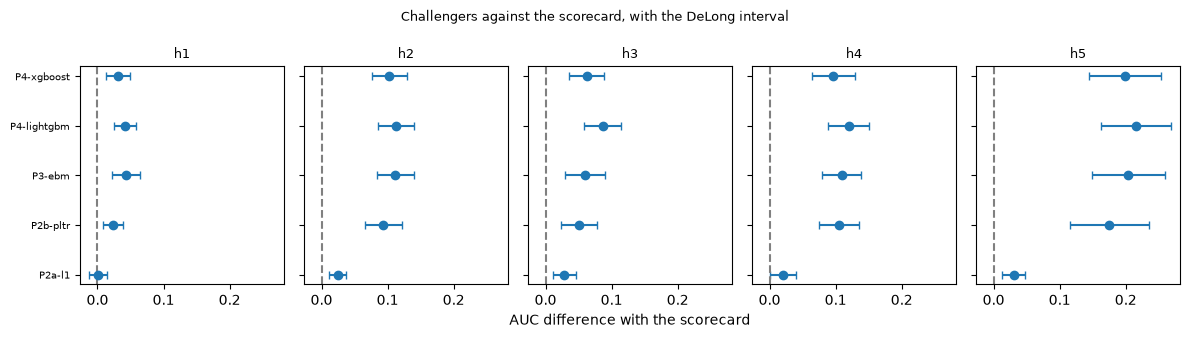

DeLong p of the LightGBM challenger by horizon: h1 1.79e-06
DeLong p of the LightGBM challenger by horizon: h2 6.26e-16
DeLong p of the LightGBM challenger by horizon: h3 1.45e-09
DeLong p of the LightGBM challenger by horizon: h4 1.64e-14
DeLong p of the LightGBM challenger by horizon: h5 2.17e-15


In [6]:
# The AUC difference of each challenger with the scorecard and its DeLong interval, and the p-value from the interval
z975 = stats.norm.ppf(0.975)
fig, axes = plt.subplots(1, 5, figsize=(12, 3.4), sharex=True)
for ax, h in zip(axes, horizons):
    rows = docs[h]["outputs"]["challenger"]
    names_ = [c["challenger"].split("-", 1)[1] for c in rows]
    diff = np.array([c["auc_diff"] for c in rows])
    lo = diff - np.array([c["auc_diff_ci"]["lo"] for c in rows])
    hi = np.array([c["auc_diff_ci"]["hi"] for c in rows]) - diff
    ax.errorbar(diff, range(len(rows)), xerr=[lo, hi], fmt="o", capsize=3)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(range(len(rows)), names_ if h == "h1" else [""] * len(rows), fontsize=7)
    ax.set_title(h, fontsize=9)
axes[2].set_xlabel("AUC difference with the scorecard")
fig.suptitle("Challengers against the scorecard, with the DeLong interval", fontsize=9)
fig.tight_layout()
plt.show()
for h in horizons:
    row = next(c for c in docs[h]["outputs"]["challenger"] if c["challenger"].endswith("lightgbm"))
    se = (row["auc_diff_ci"]["hi"] - row["auc_diff_ci"]["lo"]) / (2 * z975)
    p_value = 2 * stats.norm.sf(abs(row["auc_diff"] / se))
    print("DeLong p of the LightGBM challenger by horizon:", h, float(f"{p_value:.3g}"))

The penalised logistic regression (P2a) ties the scorecard at one year (difference 0.001, p of 0.9) and at four years sits at the edge (0.048); every other challenger beats it with an AUC gain that grows from about 0.04 at one year to about 0.2 at five. The p-value of LightGBM is 1.79e-06, 6.26e-16, 1.45e-09, 1.64e-14 and 2.17e-15 from one to five years. The growth with the horizon is the same story as the overfit gap seen from the other side: the scorecard is the weakest where the data is scarcest. The test is paired and each interval is wide, so a single horizon cannot rank the challengers among themselves.

### Step 5: calibration, model by model and horizon by horizon

Ranking is half of the question. For calibration the committed reliability bins give, for each model and horizon, ten groups of companies by PD with their mean PD and observed bankruptcy rate. As in notebook 03, the cell rebuilds the holdout from them, giving each company the PD of its bin and each bin its observed number of bankruptcies, and calls `pd_hosmer_lemeshow` with ten groups, which reproduces the committed statistic. The grid shows the p-value of every model and horizon, coloured by the light the policy gives it.

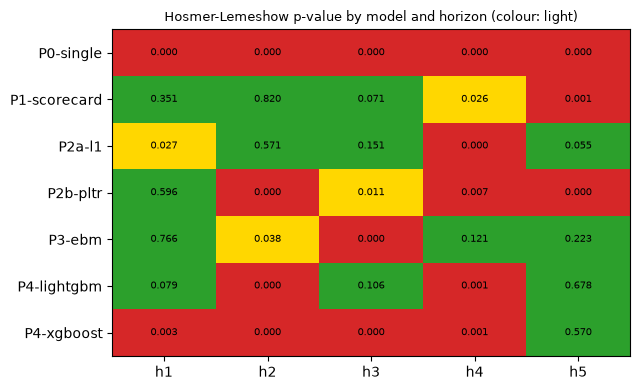

Hosmer-Lemeshow p of the scorecard by horizon: [3.511e-01 8.203e-01 7.050e-02 2.580e-02 5.000e-04]


In [7]:
# Rebuild the holdout cards from the ten reliability bins of each model and horizon and run Hosmer-Lemeshow
colors = {"green": 1, "amber": 2, "red": 3, "not_evaluated": 0}
light_grid = np.zeros((len(rungs_), len(horizons)))
p_grid = np.zeros_like(light_grid)
for j, h in enumerate(horizons):
    for i, r in enumerate(docs[h]["outputs"]["rungs"]):
        bins_ = r["reliability"]
        pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
        hits = [int(round(b["dr"] * b["n"])) for b in bins_]
        flags = np.concatenate([np.r_[np.ones(k), np.zeros(b["n"] - k)] for b, k in zip(bins_, hits)])
        kw = dict(policy=policy, model_id=r["model_id"], segment="portfolio")
        hl = pd_hosmer_lemeshow(flags, pd_cards, groups=10, **kw)
        p_grid[i, j], light_grid[i, j] = hl.p_value, colors[hl.light.value]
fig, ax = plt.subplots(figsize=(6.5, 4))
cmap = ListedColormap(["lightgray", "tab:green", "gold", "tab:red"])
ax.imshow(light_grid, cmap=cmap, vmin=0, vmax=3, aspect="auto")
for i in range(len(rungs_)):
    for j in range(len(horizons)):
        ax.text(j, i, f"{p_grid[i, j]:.3f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(5), horizons)
ax.set_yticks(range(len(rungs_)), rungs_)
ax.set_title("Hosmer-Lemeshow p-value by model and horizon (colour: light)", fontsize=9)
fig.tight_layout()
plt.show()
print("Hosmer-Lemeshow p of the scorecard by horizon:", np.round(p_grid[1], 4))

No model is green at all five horizons. The one-variable baseline is red everywhere (p of 0.0), which is natural for a model with a handful of distinct PDs. The scorecard is green at one, two and three years (0.3511, 0.8203, 0.0705), amber at four (0.0258) and red at five (0.0005). LightGBM, the best ranker, is green at one, three and five years and red at two and four. The calibration of a challenger is not a property of the model but of the model on a file, and with 81 to 155 bankruptcies in each holdout the test has little power at the edge. The grid does not say which model is best: it says that calibration cannot be assumed from ranking.

### Step 6: the level of the scorecard

A model can fail the fit test and still have the right average, which the one-sided level test of Jeffreys (notebook 03) asks. The cell takes, for the scorecard of each horizon, the number of companies and of bankruptcies in the holdout and the mean PD of its reliability bins, and calls `pd_jeffreys`. It prints the p-value with its light, and the Brier score committed for the same model.

In [8]:
# The Jeffreys level test of the scorecard of each horizon, with its committed Brier score
for h in horizons:
    o = docs[h]["outputs"]
    card = next(r for r in o["rungs"] if r["rung"] == "P1")
    bins_ = card["reliability"]
    n_b = [b["n"] for b in bins_]
    d_b = [int(round(b["dr"] * b["n"])) for b in bins_]
    p_b = [b["pd"] for b in bins_]
    mean_pd = sum(n * p for n, p in zip(n_b, p_b)) / sum(n_b)
    kw = dict(policy=policy, model_id=f"{h}-P1-scorecard", segment="portfolio")
    level = pd_jeffreys(sum(n_b), sum(d_b), mean_pd, **kw)
    print(h, "Jeffreys level test, p:", round(level.p_value, 4), LIGHT[level.light.value])
    print("   committed Brier score:", round(card["calibration"]["brier"], 4))

h1 Jeffreys level test, p: 0.8086 green
   committed Brier score: 0.0457
h2 Jeffreys level test, p: 0.4518 green
   committed Brier score: 0.0441
h3 Jeffreys level test, p: 0.3835 green
   committed Brier score: 0.0385
h4 Jeffreys level test, p: 0.4272 green
   committed Brier score: 0.0321
h5 Jeffreys level test, p: 0.6061 green
   committed Brier score: 0.0369


The level test is green at all five horizons (p of 0.8086, 0.4518, 0.3835, 0.4272 and 0.6061), including the horizons where Hosmer-Lemeshow is amber or red. The average PD of the scorecard is right everywhere and its fit by group is wrong at the longest horizons: the same finding as in notebook 04, found here with a different pair of tests. The Brier score falls from 0.0457 at one year to 0.0321 at four, then rises to 0.0369, and it follows the event rate more than the quality of the ranking, since a rarer event has a smaller mean squared error even for a poor model.

### Step 7: the same scorecard on another file

Each horizon file commits a **transfer** block: a model fitted on the training slice of one file and scored on the holdout of another. It is a tempting robustness check, and the file labels it exploratory for a reason. The UCI page gives no company identifier, so the same company may appear in several files (a company observed in the third year and again in the fifth), and a model fitted on one file may be scored on companies it has partly seen. Any transfer AUC may then be inflated, and no out-of-time claim is made. The diagonal is the model scored on its own holdout. The cell builds the matrix for the scorecard from the five files and draws it.

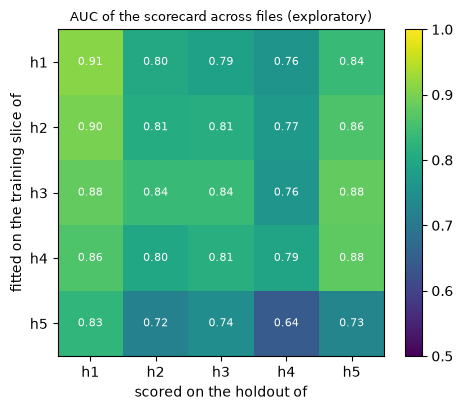

[0.911 0.81  0.839 0.792 0.728]


In [9]:
# Build the transfer matrix of the scorecard (fitted on one file, scored on another) and draw it
matrix = np.zeros((5, 5))
for fitted, h in enumerate(horizons):
    for cell in docs[h]["outputs"]["transfer"]["cells"]:
        if cell["rung"] == "P1":
            matrix[fitted, cell["scored_on_years"] - 1] = cell["auc"]
fig, ax = plt.subplots(figsize=(5, 4.2))
image = ax.imshow(matrix, vmin=0.5, vmax=1.0, cmap="viridis")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.set_xticks(range(5), [f"h{j + 1}" for j in range(5)])
ax.set_yticks(range(5), [f"h{i + 1}" for i in range(5)])
ax.set_xlabel("scored on the holdout of")
ax.set_ylabel("fitted on the training slice of")
ax.set_title("AUC of the scorecard across files (exploratory)", fontsize=9)
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()
print(np.round(np.diag(matrix), 3))

The diagonal, 0.911, 0.81, 0.839, 0.792 and 0.728, is the AUC of the scorecard on its own holdout. The off-diagonal cells are as high or higher: a scorecard fitted on the three-year file reaches 0.879 on the five-year holdout, where the one fitted on the five-year file reaches 0.728. That is not evidence that the three-year model is better; it is the expected signature of firms that repeat across files, and the reason the block is exploratory. The matrix says that a number outside the diagonal must not be reported as an out-of-sample AUC.

### Step 8: the five files stacked

The pooled file stacks the five files with a horizon indicator, so a single model sees 43,405 company-years. It has more data and a tighter interval, and it carries the same caveat in full: whether a company repeats across the files is unknown, so a company may sit in the training slice and in the holdout under different horizons. The cell rebuilds the pooled holdout from the ROC steps of each model, and compares the AUC of the engine with the mean of the five per-horizon AUC.

In [10]:
# Rebuild the pooled holdout from the ROC steps of every model and compare the engine's AUC with the horizon average
po = pooled["outputs"]
n_pos = po["split"]["holdout_events"]
n_neg = po["split"]["holdout_rows"] - n_pos
for r in po["rungs"]:
    pos = np.rint(np.diff(r["roc"]["tpr"]) * n_pos).astype(int)
    neg = np.rint(np.diff(r["roc"]["fpr"]) * n_neg).astype(int)
    risk = np.repeat(np.arange(len(pos), 0, -1), pos + neg)
    flags = np.concatenate([np.r_[np.ones(p), np.zeros(q)] for p, q in zip(pos, neg)])
    result = disc_auc(risk, flags, policy=policy, model_id=r["model_id"])
    name = r["model_id"].split("-", 1)[1]
    mean_five = np.mean([auc[(h, name)][0] for h in horizons])
    print(name, "pooled AUC, mean of the horizons:", round(result.metric, 4), round(float(mean_five), 4))

P0-single pooled AUC, mean of the horizons: 0.6519 0.7023
P1-scorecard pooled AUC, mean of the horizons: 0.8647 0.8157
P2a-l1 pooled AUC, mean of the horizons: 0.8822 0.8366
P2b-pltr pooled AUC, mean of the horizons: 0.9166 0.9052
P3-ebm pooled AUC, mean of the horizons: 0.945 0.9214
P4-lightgbm pooled AUC, mean of the horizons: 0.9703 0.9309
P4-xgboost pooled AUC, mean of the horizons: 0.9642 0.914


## Results

**Answer:** No term structure can be read from these files, and the ladder ranks and calibrates unevenly across horizons. The five event rates, 0.0694, 0.0526, 0.0471, 0.0393 and 0.0386, fall with the horizon where a cumulative PD would rise, so the files are five different samples and no lifetime loss is computed. On the holdouts rebuilt from the ROC steps the engine gives the scorecard an AUC of 0.9104, 0.8102, 0.8389, 0.7916 and 0.7275 from one to five years, while the boosted models stay above 0.9; the challengers beat it with DeLong p-values as small as 2.17e-15 (LightGBM at five years), except the penalised logistic regression at one year. The scorecard overfits where the data is scarce: the gap exceeds the tolerance at four and five years, and 1, 4, 4, 6 and 6 models of seven are flagged at the five horizons. Calibration by group is not guaranteed by ranking: the Hosmer-Lemeshow p-value of the scorecard is 0.3511, 0.8203, 0.0705, 0.0258 and 0.0005, while its level test is green at all five horizons (p of 0.8086 to 0.3835). In the stacked file the engine gives the scorecard an AUC of 0.8647 against an average of 0.8157 over the five horizons, a difference the firm overlap prevents us from reading as a gain.

What this notebook does not show: any out-of-time claim, since the files have no date and no company identifier; the characteristic stability of the 64 ratios; and a refit, which needs the raw files under the data root. With 81 to 155 bankruptcies per holdout, the intervals are wide, which is the main limit of this case.

## Summary

- Five files of different forecast years are five samples, not one cohort: their event rates fall with the horizon, and no term structure or lifetime loss is read from them.
- The ladder is compared on each horizon with the engine's AUC on holdouts rebuilt from the ROC steps and with DeLong intervals; the overfit gap flags the longest horizons, where few bankruptcies meet 64 ratios.
- Hosmer-Lemeshow rebuilt from reliability bins shows that no model is calibrated at every horizon, and that the level test can be green where the fit test is red.
- A cross-file transfer and a pooled model are exploratory: without a company identifier they cannot be called out-of-sample.

**What to try next.** Pick the horizon where the scorecard is weakest, h5, and print its reliability bins from `h5.json` beside those of LightGBM; then continue with notebook 06, which runs the current challengers against the scorecard on the Taiwan cards.

## References

- Tomczak, S. (2016), Polish Companies Bankruptcy, UCI Machine Learning Repository (CC BY 4.0), https://doi.org/10.24432/C5F600 (the attribution recorded in `data/derived/C02/raw-sources.txt`). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf